# A tour of the STARfinder processing report: make, read and compare the reports of a synthetic sample

This notebook introduces §2.11 of the maintained Python package: the **processing report** of a
sample, which reads the records that a sample's processing saved and writes one folder per sample
with a page `report.html`, a record `report.json` and the tables under `tables/`, and the
**comparison page** of a dataset, which puts finished sample reports side by side. The code
lives in `starfinder.report`, and `Dataset` in `starfinder.dataset` holds the two entries,
`Dataset.report` and `Dataset.compare_samples`. Like the §2.6 to §2.10 tours
(`starfinder_registration_tour.ipynb`, `starfinder_spot_finding_tour.ipynb`,
`starfinder_readout_tour.ipynb`, `starfinder_segmentation_assignment_tour.ipynb`,
`starfinder_stitching_assembly_tour.ipynb`), it runs every piece through the public API, on a
small synthetic sample:

1. what the report is and is not;
2. a synthetic sample (`sample-tiny-v1`);
3. `FOV.run` with checkpoints, and the records of `run.json`;
4. a report after the per-FOV processing;
5. segmentation by mask import, assignment, placement and export;
6. a report after the export;
7. reading `report.json`, `fovs.csv` and `unavailable.csv`;
8. limits and the Problematic FOVs table;
9. the route after fusion on the single-plane scene;
10. `Dataset.compare_samples`;
11. clean up.

The design is specified in three pages accepted at the review W-387 on 2026-10-12:
[docs/report-baseline.md](../../docs/report-baseline.md) (what existed before the report, and
where each value comes from), [docs/report-contract.md](../../docs/report-contract.md) (the
entries, the inputs, the tables, the reasons and the records added to `run.json`) and
[docs/report-algorithms.md](../../docs/report-algorithms.md) (how each value and figure is
computed, the layout of the page and the validation design). The notebook links those pages
rather than repeating them.

**The report describes a run; it judges nothing.** It gives no pass or fail verdict and no
composite score, and it filters and corrects nothing. The table of problematic FOVs lists where
a value lies outside a limit that the user sets; a row is a pointer, not a grade, and the
default limits are provisional (section 8). This notebook is an engineering tour, not a
benchmark: the sample is synthetic, its placement is the scene's truth and its cells are imported
from the scene's truth labels, so nothing printed here is an accuracy statement about a method or
a biological statement about a sample.

**Scope and resources.** The sample is the `sample-tiny-v1` preset of the synthetic sample scene
(seed 42): 2 × 2 FOVs of 5 × 36 × 36 voxels, four rounds of four channels; section 9 uses its
single-plane form `scene_plane` (FOVs of 1 × 36 × 36). The notebook needs no real data, MATLAB,
Fiji, GPU, browser, network access or model file. Two optional extras serve most of it:
`anndata` (`sample.h5ad`, which `Dataset.export` writes and the report reads) and
`multiview-stitcher` (the fused images of the export). Without them, the cells from section 5
print why they are skipped. Every random draw comes from a fixed seed, dask runs with the
synchronous scheduler and the numerical libraries run on one thread, so a second execution
prints the same values on the same host and library build, except the wall-clock times and the
file sizes that section 11 prints. Files are written only under a temporary directory that the
notebook creates and removes in its last cell; one execution stays within one CPU, 4 GiB and
1800 s.

To execute it from `src/python` in the locked environment (the `dev` group provides Jupyter),
with one numerical thread and no GPU:

```bash
export OMP_NUM_THREADS=1 MKL_NUM_THREADS=1 OPENBLAS_NUM_THREADS=1 CUDA_VISIBLE_DEVICES=""
uv run jupyter nbconvert --to notebook --execute --output-dir <new directory> \
    ../../example/introduction/starfinder_report_tour.ipynb
```

The setup cell keeps the numerical libraries on one thread (set before NumPy is imported) and
hides any GPU. It checks that `starfinder` is imported from the checkout that holds this
notebook, then tries each optional extra once and records which are importable. Everything the
notebook writes goes to a new temporary workspace, which section 11 removes. The helpers defined
here:

* `clean` writes that workspace as `<workspace>`, so no machine-specific path is printed;
* `skipped` prints why a cell does not run;
* `timed` records the wall time of the slower steps for section 11;
* `synchronous` runs dask's synchronous scheduler (one thread, a fixed order);
* `files_under` lists the files of a folder;
* `read_table` reads a table of a report folder with the dtypes that its `report.json` records.

The deprecation warnings that some libraries issue on import are silenced there, and so is
`ome_zarr`'s informational logging, because both print environment-specific text.

In [1]:
%matplotlib inline
import os

for variable in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS", "NUMEXPR_NUM_THREADS",
                 "NUMBA_NUM_THREADS"):
    os.environ.setdefault(variable, "1")
os.environ.setdefault("CUDA_VISIBLE_DEVICES", "")

import dataclasses
import hashlib
import importlib
import inspect
import json
import logging
import re
import shutil
import tempfile
import time
import warnings
from contextlib import contextmanager, nullcontext
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import starfinder
import starfinder.report

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)
pd.set_option("display.max_colwidth", 80)
pd.set_option("display.max_rows", 120)

REPOSITORY = Path(starfinder.__file__).resolve().parents[3]
print("starfinder imported from:", Path(starfinder.__file__).resolve().relative_to(REPOSITORY).as_posix())
print("the same checkout as this notebook:", Path.cwd().resolve().is_relative_to(REPOSITORY))
print("threads:", {v: os.environ[v] for v in ("OMP_NUM_THREADS", "NUMBA_NUM_THREADS")},
      " CUDA_VISIBLE_DEVICES:", repr(os.environ["CUDA_VISIBLE_DEVICES"]))


def importable(name):
    # Whether an optional extra can be imported; the import happens here, once, without the libraries'
    # own deprecation warnings (they name files of the environment, not of this notebook).
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        try:
            importlib.import_module(name)
        except ImportError:
            return False
    return True


EXTRAS = {"anndata": importable("anndata"), "multiview-stitcher": importable("multiview_stitcher")}
print("extras importable:", EXTRAS)
# ome_zarr logs a line with an object address when a library reads a label image back; keep it quiet.
logging.getLogger("ome_zarr").setLevel(logging.ERROR)

_workspace = tempfile.TemporaryDirectory(prefix="starfinder-report-tour-")
WORKSPACE = Path(_workspace.name)
TIMINGS = {}


def clean(text):
    # Write the temporary workspace as <workspace>.
    return str(text).replace(str(WORKSPACE.resolve()), "<workspace>").replace(str(WORKSPACE), "<workspace>")


def skipped(reason):
    print(f"skipped: {reason}")


@contextmanager
def timed(label):
    start = time.perf_counter()
    yield
    TIMINGS[label] = time.perf_counter() - start


def synchronous():
    # dask's synchronous scheduler when dask is importable (it comes with the multiview-stitcher extra).
    try:
        import dask
    except ImportError:
        return nullcontext()
    return dask.config.set(scheduler="synchronous")


def files_under(root):
    # The relative POSIX paths of the files under root, sorted.
    return sorted(p.relative_to(root).as_posix() for p in Path(root).rglob("*") if p.is_file())


def read_table(folder, name, record):
    # The table <name>.csv that a record lists (tables/<name>.csv of a report, samples.csv of the comparison), read
    # with its recorded dtypes in the CSV form of docs/checkpoints.md ("Table formats"): a missing value is written
    # <NA>; strings are read verbatim, and a literal string that starts with a backslash lost one on writing.
    entry = next(e for e in record["files"] if e["path"] in (f"tables/{name}.csv", f"{name}.csv"))
    dtypes = entry["dtypes"]
    strings = [c for c, d in dtypes.items() if d == "string"]
    frame = pd.read_csv(Path(folder) / entry["path"], keep_default_na=False, float_precision="round_trip",
                        dtype={c: object if c in strings else d for c, d in dtypes.items()},
                        na_values={c: ["<NA>"] for c in dtypes if c not in strings})
    for column in strings:
        text = frame[column].astype("string")
        missing = text.eq("<NA>")
        text = text.mask(text.str.startswith("\\"), text.str.slice(1))
        frame[column] = text.mask(missing, pd.NA)
    return frame.astype(dtypes)


print("workspace: a new temporary directory, removed at the end")

starfinder imported from: src/python/starfinder/__init__.py
the same checkout as this notebook: True
threads: {'OMP_NUM_THREADS': '1', 'NUMBA_NUM_THREADS': '1'}  CUDA_VISIBLE_DEVICES: ''


extras importable: {'anndata': True, 'multiview-stitcher': True}
workspace: a new temporary directory, removed at the end


## 1. What the report is and is not

**Terms** ([docs/report-contract.md](../../docs/report-contract.md), "Terms", "The sample
entry", "The comparison entry"):

* the **sample report** is the folder `<output>/report/<sample>/`: the page `report.html`, the
  record `report.json` and the tables `tables/<name>.csv`. `Dataset.report(sample, fov_ids, …)`
  writes it. It is a sample-level **reader**, not a runner: it calls no processing stage, reads
  only the records saved at their fixed places under the output root (each FOV's
  `checkpoints/<fov>/run.json`, the saved transforms, the per-FOV segmentation and assignment,
  the reference images, `stitching/<sample>/` and `export/<sample>/`) and the raw input of one
  example FOV, which it replays, and it writes only its own folder. A second report of a sample
  replaces the first as a whole (RP1);
* a **part** is one block of the page (`REPORT_PARTS`, in page order, in eight sections). A
  part, or one value of it, whose input does not exist is **unavailable** with exactly one reason
  of the closed list `UNAVAILABLE_REASONS`, recorded once in `tables/unavailable.csv`; the entry
  does not raise for a missing input (section 7);
* the **problematic FOVs** are the FOVs that a rule of `PROBLEM_RULES` marks: a categorical
  rule (a failed run, a FOV not placed) or a value outside a limit of `ReportLimits` (section 8);
* the **comparison page** `<output>/report/index.html`, with `samples.csv`, is written by
  `Dataset.compare_samples(samples)` from finished sample reports only (section 10).

**What it is not.** No verdict: no pass or fail state, no grade and no composite score, in the
page, the tables or the record. No filtering, correction or normalization of any value. The
validation of the report (the table "Implemented checks (W-459)" of
[docs/report-algorithms.md](../../docs/report-algorithms.md)) establishes **engineering**
correctness, that the records are read and combined as the pages state; it does not show that a
sample is well processed or that a method is accurate.

The cell prints both signatures, the closed lists and the configuration the user supplies,
`ReportConfig`, at its defaults.

In [2]:
from starfinder.dataset import Dataset
from starfinder.report import (PROBLEM_RULES, REPORT_PARTS, REPORT_TABLES, UNAVAILABLE_REASONS, ReportConfig,
                               read_report)

for entry in (Dataset.report, Dataset.compare_samples):
    print(f"Dataset.{entry.__name__}{str(inspect.signature(entry)).replace('(self, ', '(')}")
print("\nREPORT_PARTS, by section of the page:")
for section in dict.fromkeys(p.split(".")[0] for p in REPORT_PARTS):
    print(f"  {section:14s}", [p for p in REPORT_PARTS if p.split(".")[0] == section])
print("REPORT_TABLES:", REPORT_TABLES)
print("PROBLEM_RULES:", PROBLEM_RULES)
print("UNAVAILABLE_REASONS:", UNAVAILABLE_REASONS)
print("\nReportConfig():", ReportConfig())

Dataset.report(sample: 'str', fov_ids, *, assignment: 'str | None' = 'default', segmentation: 'str | None' = None, config=None, output_dir=None)
Dataset.compare_samples(samples, *, report_root=None)

REPORT_PARTS, by section of the page:
  summary        ['summary.identity', 'summary.key_numbers', 'summary.problematic_fovs']
  workflow       ['workflow.steps', 'workflow.fov_status', 'workflow.time']
  preprocessing  ['preprocessing.example', 'preprocessing.intensity']
  registration   ['registration.maps', 'registration.heatmap', 'registration.example']
  readout        ['readout.totals', 'readout.per_fov', 'readout.distributions', 'readout.table']
  assembly       ['assembly.cells_per_fov', 'assembly.placement', 'assembly.examples', 'assembly.accounting']
  sample         ['sample.per_cell', 'sample.markers', 'sample.marker_zoom', 'sample.mecr', 'sample.reads_along_z']
  files          ['files.input', 'files.configuration', 'files.output']
REPORT_TABLES: ('fovs', 'registration', 'step

**Where the accepted pages live.** The cell prints their titles and status lines from the files.

In [3]:
for page in ("report-baseline", "report-contract", "report-algorithms"):
    lines = (REPOSITORY / "docs" / f"{page}.md").read_text().splitlines()
    status = next(line for line in lines if line.startswith("Status:"))
    print(f"docs/{page}.md: {lines[0].lstrip('# ')}\n    {status}")

docs/report-baseline.md: Processing-report baseline: the legacy QC notebook, today's diagnostics, the records the report reads and their gaps
    Status: Accepted (W-387, 2026-10-12, at c0aa8b0)
docs/report-contract.md: Processing-report contract: the sample report, the comparison page, their inputs, tables and record, and the records added to `run.json`
    Status: Accepted (W-387, 2026-10-12, at c0aa8b0)
docs/report-algorithms.md: Processing-report algorithms, layout and validation design
    Status: Accepted (W-387, 2026-10-12, at c0aa8b0; the grid-edge mark of the reads along Z written on at 06466ec)


## 2. A synthetic sample

The sample is the `sample-tiny-v1` preset
([docs/synthetic-sample-scene.md](../../docs/synthetic-sample-scene.md), "Presets and
resources"), seed 42: one scene in continuous sample coordinates, from which each FOV of a 2 × 2
grid is rendered at its true origin, with four rounds of four channels (`float32`), a nuclear
stain and truth label images (nuclei and cells) on each FOV's grid. `save_sample_scene` writes
the scene with its truth tables, among them `positions.csv` (the nominal tile positions) and
`placement_truth.csv` (the true origins).

The report reads the records of a run, and a run record names the raw files it loaded. So the
cell writes each FOV's rounds as the input of a dataset, one OME-TIFF per channel at
`input/<round>/<fov>/<channel>.ome.tif` with the FOV's metadata, which `FOV.run` loads and
`run.json` lists with their SHA-256. This is the layout of the fixture `scene_chain` of the
report's validation design ([docs/report-algorithms.md](../../docs/report-algorithms.md),
"Fixtures").

In [4]:
from starfinder.io import save_volume
from starfinder.synthetic import SAMPLE_PRESET_VERSION, generate_sample_scene, sample_scene_preset, save_sample_scene


def write_inputs(scene, rounds, channels, root):
    # One OME-TIFF per round, FOV and channel, in the dataset layout input/<round>/<fov>/<channel>.ome.tif.
    for fov, formed in scene.fovs.items():
        for r in rounds:
            for c, channel in enumerate(channels):
                save_volume(formed.rounds[r][..., c:c + 1], root / r / fov / f"{channel}.ome.tif",
                            metadata=scene.fov_metadata[fov])


book, config = sample_scene_preset("sample-tiny-v1")
with timed("sample-tiny-v1: generate and save the scene, write the inputs"):
    scene = generate_sample_scene(book, config=config)
    SCENE = WORKSPACE / "tiny" / "scene"
    save_sample_scene(scene, SCENE)
    SAMPLE, DATASET = scene.sample, config.fov.dataset_version
    ROUNDS = list(next(iter(scene.fovs.values())).round_labels)
    CHANNELS = list(book.channel_labels)
    INPUT, OUTPUT = WORKSPACE / "tiny" / "input", WORKSPACE / "tiny" / "output"
    write_inputs(scene, ROUNDS, CHANNELS, INPUT)
FOV_IDS = list(scene.positions.fov_id)
print("preset version:", SAMPLE_PRESET_VERSION, " dataset:", DATASET, " sample:", SAMPLE, " seed:", config.fov.seed)
print("FOVs:", FOV_IDS, " FOV shape (ZYX):", config.acquisition.fov_shape_zyx,
      " spacing (µm):", config.acquisition.spacing_zyx)
print("rounds:", ROUNDS, " channels:", CHANNELS, " codebook:", book)
print("input files:", len(files_under(INPUT)), " for example:", files_under(INPUT)[:2])

preset version: sample-presets-v1  dataset: sample-tiny-v1  sample: sample  seed: 42
FOVs: ['FOV_001', 'FOV_002', 'FOV_003', 'FOV_004']  FOV shape (ZYX): (5, 36, 36)  spacing (µm): (1.0, 0.5, 0.5)
rounds: ['round1', 'round2', 'round3', 'round4']  channels: ['ch00', 'ch01', 'ch02', 'ch03']  codebook: Codebook: 16 genes × 4 rounds, channels ch00, ch01, ch02, ch03; encoding two_base, one segment of 4 colors
input files: 64  for example: ['round1/FOV_001/ch00.ome.tif', 'round1/FOV_001/ch01.ome.tif']


## 3. `FOV.run` with checkpoints, and the records of `run.json`

`FOV.run(pipeline, checkpoints=CheckpointConfig(…))` writes the FOV's **run record**
`checkpoints/<fov>/run.json` ([docs/checkpoints.md](../../docs/checkpoints.md)): its identity,
inputs, configuration, steps with their times, status, counts and the records of each stage.
§2.11 added four records that the report reads
([docs/report-contract.md](../../docs/report-contract.md), "Records added to `run.json`"),
without a change of the format version (V1):

* **R1** `transforms`: the transform of every moving round, so that the registration's shifts
  and the replay of the example need no saved `registered/` stage;
* **R2** `codebook`: the codebook with its file and SHA-256, so that the marker genes are checked
  against the run's gene list. Here the codebook is the scene's, set on the `Dataset` without a
  file, so `path` and `sha256` are null, as the contract states for that case; the report then
  checks the marker genes against the export's gene list;
* **R3** `counts.filtering.endpoint_valid`: the reads of the correct form, whose segment ends
  are a declared pair. It is present exactly when the filter checked endpoints, as here
  (`end_bases="CC"`); the count per segment, `endpoint_valid_segments`, comes with a codebook
  layout whose segments have ends, which this codebook does not have;
* **R4** `workflow_config`: the workflow's configuration file; null for a run made from Python,
  as here.

The pipeline is the synthetic recipe of the report's fixture `scene_chain`: min–max
normalization to uint8 and a white top-hat of radius 3, one translation step on the channel
maximum, local maxima, extraction, the WTA decoder, the shared score, deduplication and a filter
with segment ends. It is a choice for this demonstration, not a recommendation. The checkpoint
stages are `candidates` and `pre_qc`; the stage `registered` is off, so the transforms come from
R1. After each run the cell saves the FOV's reference image (`images/ref_merged/<fov>.tif`,
which the report reads for the Z size and the segmentation examples) and its goodSpots table, as
the workflow's rule does.

In [5]:
from starfinder.barcode import (DeduplicationConfig, NeighborhoodSumConfig, ReadFilterConfig, ReadScoreConfig,
                                WtaDecoderConfig)
from starfinder.dataset import CheckpointConfig, PipelineConfig, RoundState
from starfinder.registration import RegistrationRecipe, RegistrationStep
from starfinder.io import ImageLoadConfig
from starfinder.preprocessing import MinMaxNormalizationConfig, PreprocessingRecipe, PreprocessingStep, TophatConfig
from starfinder.registration import RegistrationSignalConfig, TranslationConfig
from starfinder.spot_finding import LocalMaximaConfig

PIPELINE = PipelineConfig(
    load=ImageLoadConfig(channel_labels=tuple(CHANNELS)),
    preprocessing=PreprocessingRecipe((
        PreprocessingStep(MinMaxNormalizationConfig("uint8", (0, 255), rounding="truncate")),
        PreprocessingStep(TophatConfig(radius_yx=3)))),
    registration=RegistrationRecipe(steps=(RegistrationStep(TranslationConfig()),),
                                    signal=RegistrationSignalConfig(mode="max")),
    spot_finding=LocalMaximaConfig(exclude_border=False), extraction=NeighborhoodSumConfig(),
    decoding=WtaDecoderConfig(negative_policy="clip_negative"), scoring=ReadScoreConfig(),
    deduplication=DeduplicationConfig(), filtering=ReadFilterConfig(end_bases="CC", start_base="C"))
STAGES = ("candidates", "pre_qc")


def make_dataset(input_root, output_root, scene, book):
    dataset = Dataset(input_root, output_root, DATASET, scene.sample, "output",
                      rounds=RoundState(sequencing_rounds=ROUNDS, reference_round=ROUNDS[0]), channel_order=CHANNELS)
    dataset.codebook = book
    return dataset


def run_fovs(dataset, fov_ids, checkpoints):
    # FOV.run with checkpoints on every FOV, then the rule outputs: the reference image and the goodSpots table.
    fovs = {}
    for fov_id in fov_ids:
        fov = dataset.fov(fov_id)
        fov.run(PIPELINE, checkpoints=checkpoints)
        fov.save_reference_image()
        fov.save_spots()
        fovs[fov_id] = fov
    return fovs


dataset = make_dataset(INPUT, OUTPUT, scene, book)
CHECKPOINTS = CheckpointConfig(stages=STAGES, directory=OUTPUT / "checkpoints")
with timed("sample-tiny-v1: FOV.run with checkpoints (4 FOVs)"):
    FOVS = run_fovs(dataset, FOV_IDS, CHECKPOINTS)
print("files of FOV_001 under the output root:")
for path in files_under(OUTPUT):
    if "FOV_001" in path:
        print("  ", path)

files of FOV_001 under the output root:
   checkpoints/FOV_001/candidates.csv
   checkpoints/FOV_001/candidates.json
   checkpoints/FOV_001/pre_qc.csv
   checkpoints/FOV_001/pre_qc.json
   checkpoints/FOV_001/run.json
   images/ref_merged/FOV_001.tif
   signal/FOV_001_goodSpots.csv


The cell reads the four run records back as JSON and prints the records R1 to R4, with the
counts that the report's readout reads (`counts.spots`, `call_status.assigned`,
`deduplication.merged_reads`, `filtering.accepted`). It asserts that `transforms`, `codebook` and
`counts.filtering.endpoint_valid` are present in every run record and that the transforms name
every moving round.

In [6]:
def run_record(output_root, fov):
    return json.loads((Path(output_root) / "checkpoints" / fov / "run.json").read_text())


RUNS = {fov: run_record(OUTPUT, fov) for fov in FOV_IDS}
first = RUNS[FOV_IDS[0]]
print("format_version:", first["format_version"], " status:", first["status"])
print("top-level keys:", list(first))
print("\ntransforms of FOV_001 (R1), per moving round:")
for round_name, entry in first["transforms"].items():
    steps = [(r["step"], r["transform"].get("kind", sorted(r["transform"])[0])) for r in entry["results"]]
    print(f"  {round_name}: reference {entry['reference']}, results (step, kind): {steps}")
print("codebook (R2):", first["codebook"])
print("counts.filtering (R3):", first["counts"]["filtering"])
print("workflow_config (R4):", first["workflow_config"])
display(pd.DataFrame([dict(fov_id=fov, status=r["status"], spots=r["counts"]["spots"],
                           endpoint_valid=r["counts"]["filtering"]["endpoint_valid"],
                           assigned=r["counts"]["call_status"].get("assigned", 0),
                           merged_reads=r["counts"]["deduplication"]["merged_reads"],
                           accepted=r["counts"]["filtering"]["accepted"]) for fov, r in RUNS.items()]))

for fov, record in RUNS.items():
    assert "transforms" in record and "codebook" in record and "endpoint_valid" in record["counts"]["filtering"], fov
    assert set(record["transforms"]) == set(ROUNDS[1:]), fov
    assert record["codebook"]["genes"] == len(book.genes) and record["status"] == "succeeded", fov
print("the keys transforms, codebook and counts.filtering.endpoint_valid are in every run record: True")

format_version: 1  status: succeeded
top-level keys: ['format_version', 'dataset_id', 'sample_id', 'fov_id', 'subtile_id', 'status', 'started_at', 'ended_at', 'error', 'code', 'environment', 'config', 'workflow_config', 'channels', 'inputs', 'codebook', 'steps', 'preprocessing', 'registration', 'transforms', 'counts', 'checkpoint_directory', 'checkpoints']

transforms of FOV_001 (R1), per moving round:
  round2: reference round1, results (step, kind): [(0, 'translation')]
  round3: reference round1, results (step, kind): [(0, 'translation')]
  round4: reference round1, results (step, kind): [(0, 'translation')]
codebook (R2): {'kind': 'codebook', 'path': None, 'sha256': None, 'entries': 16, 'genes': 16}
counts.filtering (R3): {'total': 26, 'accepted': 24, 'rejected': 2, 'endpoint_valid': 3}
workflow_config (R4): None


,fov_id,status,spots,endpoint_valid,assigned,merged_reads,accepted
0,FOV_001,succeeded,26,3,24,0,24
1,FOV_002,succeeded,16,0,13,0,13
2,FOV_003,succeeded,33,8,29,1,28
3,FOV_004,succeeded,40,11,31,1,31


the keys transforms, codebook and counts.filtering.endpoint_valid are in every run record: True


## 4. A report after the per-FOV processing

A report can be written at any stage of a sample's processing, as soon as one FOV has a run
record ([docs/report-contract.md](../../docs/report-contract.md), "The report at each stage of a
sample's processing"). Here only the run records exist, with the reference images: no
placement, no assignment and no export. That is the first row of the contract's stage table:

| What exists | What the report holds | Unavailable, with reason |
| --- | --- | --- |
| Run records of some or all FOVs, nothing else | Summary (identity, configuration check, version, times, the key numbers up to the matched fraction), the per-FOV lane, FOV status and times, preprocessing and registration examples (replayed), the registration heatmap, the readout totals and per-FOV values, their distributions and table; the problematic FOVs of the workflow, registration and readout rules | The FOV maps (`no_placement`); Segmentation and assembly, Sample measurements, the reads assigned to cells (`no_export`); a running FOV's later values (`run_not_finished`) |

`Dataset.report(SAMPLE, FOV_IDS)` writes into the default folder `<output>/report/<sample>/`.
The cell groups the rows of `unavailable.csv` by part and reason. Two reasons do not depend on
the stage: `not_configured` (here the rule `alignment_score`, which has no default limit) and
`not_recorded` (a value or time that no record holds). Every other reason names what the stage
lacks. The cell asserts the row of the table:

* **present**, with no row of a stage's reason: the Summary's identity and problematic FOVs, the
  Workflow overview, Preprocessing, the registration heatmap and example, the readout's
  distributions and table, and the configuration and output blocks of Files;
* **present but for what the stage lacks**: the Summary's key numbers and the readout totals lack
  only the reads assigned to cells and the cell counts (`no_export`); the readout's per-FOV
  values lack only their map (`no_placement`). The reads in cells of each FOV are cells of
  `fovs.csv` that `assembly.cells_per_fov` names;
* **unavailable**: the registration maps, the placement block and the placement table of Files
  with `no_placement`; every part of Segmentation and assembly and of Sample measurements with
  `no_export`. The owned area and the cell density take `no_placement`, the first of their
  reasons in the order of `UNAVAILABLE_REASONS` (P1). The segmentation examples of the route per
  FOV read the assignment folder, which does not exist yet, so they take `input_missing`, one of
  the reasons of that part in "Parts, their inputs and their reasons".

No FOV is running, so no value is `run_not_finished`.

In [7]:
STAGE_REASONS = set(UNAVAILABLE_REASONS) - {"not_configured", "not_recorded"}


def parts_and_reasons(record):
    # part -> the reasons of its rows in report.json "unavailable" (the rows of tables/unavailable.csv).
    found = {}
    for row in record["unavailable"]:
        found.setdefault(row["part"], set()).add(row["reason"])
    return found


with timed("Dataset.report after the per-FOV processing"):
    FIRST = dataset.report(SAMPLE, FOV_IDS)
REPORT_DIR = OUTPUT / "report" / SAMPLE
print("folder:", clean(FIRST.path), " the default folder:", FIRST.path == REPORT_DIR)
print("stages:", FIRST.record["stages"], " route:", FIRST.record["route"])
first_files = files_under(REPORT_DIR)
print("files:", first_files)

found = parts_and_reasons(FIRST.record)
display(pd.DataFrame([dict(part=part, reasons=", ".join(sorted(found.get(part, ()))) or "-",
                           stage_reasons=", ".join(sorted(found.get(part, set()) & STAGE_REASONS)) or "-")
                      for part in REPORT_PARTS]))
print("rules:", {part: sorted(r) for part, r in found.items() if part.startswith("rule:")})
print("\nthe rows of summary.key_numbers, readout.totals and readout.per_fov with a stage's reason:")
display(pd.DataFrame([r for r in FIRST.record["unavailable"]
                      if r["part"] in ("summary.key_numbers", "readout.totals", "readout.per_fov")
                      and r["reason"] in STAGE_REASONS]))

PRESENT = ["summary.identity", "summary.problematic_fovs", "workflow.steps", "workflow.fov_status", "workflow.time",
           "preprocessing.example", "preprocessing.intensity", "registration.heatmap", "registration.example",
           "readout.distributions", "readout.table", "files.configuration", "files.output"]
PARTLY = {"summary.key_numbers": {"no_export"}, "readout.totals": {"no_export"}, "readout.per_fov": {"no_placement"}}
UNAVAILABLE = {"registration.maps": {"no_placement"}, "assembly.cells_per_fov": {"no_placement", "no_export"},
               "assembly.placement": {"no_placement"}, "assembly.examples": {"input_missing"},
               "assembly.accounting": {"no_export"}, "sample.per_cell": {"no_export"},
               "sample.markers": {"no_export"}, "sample.marker_zoom": {"no_export"}, "sample.mecr": {"no_export"},
               "sample.reads_along_z": {"no_export"}, "files.input": {"no_placement"}}
assert FIRST.record["stages"]["run_records"] == FOV_IDS
assert not FIRST.record["stages"]["placement"] and not FIRST.record["stages"]["export"]
assert sorted(PRESENT + list(PARTLY) + list(UNAVAILABLE)) == sorted(REPORT_PARTS)
for part in PRESENT:
    assert not found.get(part, set()) & STAGE_REASONS, part
for part, reasons in {**PARTLY, **UNAVAILABLE}.items():
    assert found.get(part, set()) & STAGE_REASONS == reasons, (part, found.get(part))
# What the partly present parts lack: the reads assigned to cells and the per-FOV map, nothing else.
READS_IN_CELLS = {"reads_in_cells", "reads_in_cells_fraction", "h5ad_whole_count_sum", "reads_in_cells_equal",
                  "counted_cells", "reads_per_cell_median", "genes_per_cell_median", "cells_median_per_fov"}
for row in FIRST.record["unavailable"]:
    if row["part"] in PARTLY and row["reason"] in STAGE_REASONS:
        assert (row["column"] in READS_IN_CELLS or row["row_key"] == "level=reads_in_cells"
                or (row["table"] is None and row["reason"] == "no_placement")), row
# Each FOV's reads in cells: a cell of fovs.csv, unavailable with no_export under assembly.cells_per_fov.
assert sorted(r["row_key"] for r in FIRST.record["unavailable"] if r["column"] == "reads_in_cells"
              and r["table"] == "fovs" and r["part"] == "assembly.cells_per_fov"
              and r["reason"] == "no_export") == [f"fov_id={f}" for f in FOV_IDS]
summary = FIRST.record["summary"]
print("\nkey numbers up to the matched fraction:",
      {k: summary[k] for k in ("fovs_expected", "fovs_with_run_record", "fovs_succeeded", "spots_median_per_fov",
                               "matched_fraction")})
assert summary["fovs_succeeded"] == len(FOV_IDS) and summary["matched_fraction"] is not None
print("present and unavailable as the first row of the stage table: True")

folder: <workspace>/tiny/output/report/sample  the default folder: True
stages: {'run_records': ['FOV_001', 'FOV_002', 'FOV_003', 'FOV_004'], 'placement': False, 'export': False, 'parts': {}}  route: None
files: ['report.html', 'report.json', 'tables/cells.csv', 'tables/fovs.csv', 'tables/intensity.csv', 'tables/mecr.csv', 'tables/population.csv', 'tables/problematic_fovs.csv', 'tables/readout_totals.csv', 'tables/reads_along_z.csv', 'tables/registration.csv', 'tables/steps.csv', 'tables/unavailable.csv']


,part,reasons,stage_reasons
0,summary.identity,-,-
1,summary.key_numbers,no_export,no_export
2,summary.problematic_fovs,-,-
3,workflow.steps,-,-
4,workflow.fov_status,-,-
5,workflow.time,-,-
6,preprocessing.example,-,-
7,preprocessing.intensity,-,-
8,registration.maps,no_placement,no_placement
9,registration.heatmap,-,-


rules: {'rule:alignment_score': ['not_configured'], 'rule:not_placed': ['no_placement'], 'rule:stage_position_fallback': ['no_placement'], 'rule:reads_no_cell': ['no_export']}

the rows of summary.key_numbers, readout.totals and readout.per_fov with a stage's reason:


,part,table,column,row_key,reason,detail
0,summary.key_numbers,summary,counted_cells,,no_export,export/sample/export.json
1,summary.key_numbers,summary,reads_per_cell_median,,no_export,export/sample/export.json
2,summary.key_numbers,summary,genes_per_cell_median,,no_export,export/sample/export.json
3,summary.key_numbers,summary,cells_median_per_fov,,no_export,export/sample/export.json
4,summary.key_numbers,summary,reads_in_cells,,no_export,export/sample/export.json
5,summary.key_numbers,summary,h5ad_whole_count_sum,,no_export,export/sample/export.json
6,summary.key_numbers,summary,reads_in_cells_equal,,no_export,export/sample/export.json
7,readout.totals,readout_totals,count,level=reads_in_cells,no_export,export/sample/export.json
8,readout.totals,readout_totals,fraction_of_spots,level=reads_in_cells,no_export,export/sample/export.json
9,readout.per_fov,NaN,NaN,,no_placement,stitching/sample/placement.json



key numbers up to the matched fraction: {'fovs_expected': 4, 'fovs_with_run_record': 4, 'fovs_succeeded': 4, 'spots_median_per_fov': 29.5, 'matched_fraction': 0.8434782608695652}
present and unavailable as the first row of the stage table: True


## 5. Segmentation by mask import, assignment, placement and export

The later stages are those of the §2.9 and §2.10 tours, shortened:

1. **Segmentation by mask import, and assignment.** `import_labels` of each FOV's truth labels
   (`labels/cells.tif`, `labels/nuclei.tif`) on the FOV's grid, with `relabel=False` so each cell
   keeps its sample cell ID, then `FOV.assign(cells=…, nuclei=…, checkpoints=…)`, which saves the
   assignment `default` under `checkpoints/<fov>/assignment/default/`. No segmenter runs. The
   nuclear stain is saved as the image `reference_stain`, which the default fused image reads;
2. **The truth placement.** `placement_from_table` on `positions.csv` with the origins of
   `placement_truth.csv`, approved with `approve_placement` (a supplied placement is never
   trusted silently) and saved with `save_placement` under `stitching/<sample>/`;
3. **The export.** `Dataset.export` on the route per FOV, with the fused image in both forms
   (`dimensionality="both"`: a projection, and a stack, which the XZ zoom of the marker patterns
   reads), into `export/<sample>/`.

The cell needs the `anndata` extra (the export writes `sample.h5ad`) and the
`multiview-stitcher` extra (the fused images).

In [8]:
from starfinder.sample_output import ExportConfig, FusionConfig
from starfinder.segmentation import ReferenceGrid, import_labels
from starfinder.stitching import approve_placement, placement_from_table, positions_from_table, save_placement

CHAIN = EXTRAS["anndata"] and EXTRAS["multiview-stitcher"]
STAIN_FILE = Path("other_rounds") / "reference_stain" / "image.ome.tif"


def assign_by_mask_import(fovs, scene_dir, scene, checkpoints):
    # The truth labels through import_labels (sample IDs kept), FOV.assign with checkpoints, the stain saved.
    for fov_id, fov in fovs.items():
        grid = fov.reference_grid()
        namespace = json.dumps([DATASET, scene.sample, fov_id, None, "truth"], separators=(",", ":"))
        labels = {target: import_labels(scene_dir / "fovs" / fov_id / "labels" / file, grid=grid, target=target,
                                        relabel=False, label_namespace=namespace)
                  for target, file in (("cell", "cells.tif"), ("nucleus", "nuclei.tif"))}
        fov.assign(cells=labels["cell"], nuclei=labels["nucleus"], checkpoints=checkpoints)
        stain = scene.stains[fov_id]
        save_volume(stain[..., None] if stain.ndim == 3 else stain, checkpoints.directory / fov_id / STAIN_FILE,
                    metadata=scene.fov_metadata[fov_id])


def save_truth_placement(scene_dir, scene, config, output_root):
    # The scene's true origins through placement_from_table, approved and saved under stitching/<sample>/.
    table = positions_from_table(scene_dir / "positions.csv")
    truth = pd.read_csv(scene_dir / "placement_truth.csv", float_precision="round_trip").set_index("fov_id")
    origins = {f: tuple(float(v) for v in truth.loc[f, ["true_origin_z", "true_origin_y", "true_origin_x"]])
               for f in table.fov_ids}
    grids = {f: ReferenceGrid(config.acquisition.fov_shape_zyx, scene.fov_metadata[f], "declared")
             for f in table.fov_ids}
    placement = approve_placement(placement_from_table(table, grids, sample=scene.sample, origins=origins),
                                  reviewer="tour", note="the truth placement, supplied")
    save_placement(placement, output_root / "stitching" / scene.sample)
    return placement, grids


if not CHAIN:
    skipped("the export needs the anndata and multiview-stitcher extras (starfinder[anndata], "
            "starfinder[multiview-stitcher]); sections 6 to 10 skip")
else:
    with timed("sample-tiny-v1: mask import and FOV.assign (4 FOVs)"):
        assign_by_mask_import(FOVS, SCENE, scene, CHECKPOINTS)
    PLACEMENT, GRIDS = save_truth_placement(SCENE, scene, config, OUTPUT)
    print("placement:", PLACEMENT.record["origins"], " review:", PLACEMENT.record["review"]["state"],
          " approvals:", len(PLACEMENT.record["review"]["approvals"]))
    EXPORT_DIR = OUTPUT / "export" / SAMPLE
    with timed("sample-tiny-v1: Dataset.export on the route per FOV (dimensionality both)"), synchronous():
        export = dataset.export(SAMPLE, placement=OUTPUT / "stitching" / SAMPLE, output_dir=EXPORT_DIR,
                                config=ExportConfig(route="per_fov", fusion=FusionConfig(dimensionality="both")))
    print("export parts:", export.parts, " complete:", export.complete)
    print("export files:", files_under(EXPORT_DIR))

placement: supplied  review: required  approvals: 1


export parts: {'assemble': 'written', 'fuse': 'written', 'segment': 'off', 'fuse_labels': 'off', 'export_spatialdata': 'off'}  complete: True
export files: ['export.json', 'reference_stain_projection.ome.tif', 'reference_stain_stack.ome.tif', 'sample.h5ad', 'tables/cells.csv', 'tables/counts.csv', 'tables/fovs.csv', 'tables/molecules.csv']


## 6. A report after the export

The same call, now that the assignment, the placement and the export exist, with a
`ReportConfig` that names two **marker groups** (the figures of the marker patterns, one to four
genes each) and two **marker pairs** (MECR, a descriptive count of the cells positive for one
gene of a pair, the other, or both; [docs/report-algorithms.md](../../docs/report-algorithms.md),
"`mecr.csv`"). The genes are the first five of the scene's codebook, chosen for the
demonstration; they are not markers of any cell type. `Dataset.report` checks each gene against
the run's gene list before anything is written.

**The check of the reads in cells.** The Summary's key number `reads_in_cells` is counted from
the export's tables: the molecules retained with a counted cell (retained, and §2.9 `kept`). The
report also sums the whole counts of `sample.h5ad` (`h5ad_whole_count_sum`, read with h5py) and
records whether the two are equal (`reads_in_cells_equal`;
[docs/report-algorithms.md](../../docs/report-algorithms.md), "Reads assigned to cells"). The
cell asserts that they are.

**The eight sections.** The page has eight sections, in this order: Summary, Workflow overview,
Preprocessing, Registration, Readout, Segmentation and assembly, Sample measurements, Files
([docs/report-algorithms.md](../../docs/report-algorithms.md), "Layout of the page"). The cell
reads the section headings of `report.html` and asserts their order. The page is one
self-contained file that a browser opens; the notebook does not open it.

**The second report replaces the first.** The folder holds only the files of the latest report
(RP1); the cell compares the file lists.

In [9]:
from starfinder.report import MarkerGroup

SECTIONS = ["Summary", "Workflow overview", "Preprocessing", "Registration", "Readout", "Segmentation and assembly",
            "Sample measurements", "Files"]

if not CHAIN:
    skipped("no export (section 5)")
else:
    GENES = list(json.loads((EXPORT_DIR / "export.json").read_text())["assembly"]["genes"])
    MARKERS = ReportConfig(markers=(MarkerGroup("first", tuple(GENES[:2])), MarkerGroup("second", tuple(GENES[2:5]))),
                           marker_pairs=((GENES[0], GENES[1]), (GENES[2], GENES[3])))
    print("marker groups:", [(m.name, m.genes) for m in MARKERS.markers], " pairs:", MARKERS.marker_pairs)
    with timed("sample-tiny-v1: Dataset.report after the export"):
        REPORT = dataset.report(SAMPLE, FOV_IDS, config=MARKERS)
    record = REPORT.record
    print("folder:", clean(REPORT.path), " stages:", record["stages"], " route:", record["route"])
    summary = record["summary"]
    print("\nsummary:")
    for key, value in summary.items():
        print(f"  {key}: {value}")
    assert summary["reads_in_cells"] == summary["h5ad_whole_count_sum"] and summary["reads_in_cells_equal"] is True
    print("reads_in_cells equals h5ad_whole_count_sum:", summary["reads_in_cells"] == summary["h5ad_whole_count_sum"])

    page = (REPORT.path / "report.html").read_text(encoding="utf-8")
    headings = [re.sub(r"<[^>]+>", "", h).strip() for h in re.findall(r"<h2[^>]*>(.*?)</h2>", page, re.S)]
    print("\nsections of report.html:", headings)
    assert headings == SECTIONS
    print("eight sections, in order:", headings == SECTIONS)

    files = files_under(REPORT.path)
    listed = sorted(["report.json"] + [e["path"] for e in record["files"]])
    print("\nfiles of the folder:", files)
    print("the folder holds exactly the files of the latest report:", files == listed)
    assert files == listed

marker groups: [('first', ('balanced-01', 'balanced-02')), ('second', ('balanced-03', 'balanced-04', 'balanced-05'))]  pairs: (('balanced-01', 'balanced-02'), ('balanced-03', 'balanced-04'))


folder: <workspace>/tiny/output/report/sample  stages: {'run_records': ['FOV_001', 'FOV_002', 'FOV_003', 'FOV_004'], 'placement': True, 'export': True, 'parts': {'assemble': 'written', 'fuse': 'written', 'segment': 'off', 'fuse_labels': 'off', 'export_spatialdata': 'off'}}  route: per_fov

summary:
  fovs_expected: 4
  fovs_with_run_record: 4
  fovs_succeeded: 4
  spots_median_per_fov: 29.5
  matched_fraction: 0.8434782608695652
  counted_cells: 8
  reads_per_cell_median: 5.0
  genes_per_cell_median: 5.0
  cells_median_per_fov: 2.0
  reads_in_cells: 51
  h5ad_whole_count_sum: 51
  reads_in_cells_equal: True
reads_in_cells equals h5ad_whole_count_sum: True

sections of report.html: ['Summary', 'Workflow overview', 'Preprocessing', 'Registration', 'Readout', 'Segmentation and assembly', 'Sample measurements', 'Files']
eight sections, in order: True

files of the folder: ['report.html', 'report.json', 'tables/cells.csv', 'tables/fovs.csv', 'tables/intensity.csv', 'tables/mecr.csv', 'table

## 7. Reading `report.json`, `fovs.csv` and `unavailable.csv`

`read_report(folder)` reads `report.json` back and checks every file of its `files` list against
the SHA-256 and the size recorded there; a file changed after the report raises `ValueError`
naming it. Each table's entry also records the table's dtypes, so a table reads back with the
types the contract gives it ([docs/report-contract.md](../../docs/report-contract.md), "The
tables"): a column that can be null has a nullable dtype (`Int64`, `boolean`), and strings are
`string`. `read_table`, defined in the setup cell, passes them to `pandas.read_csv`.

**`fovs.csv`** has one row per FOV of the list, in list order: the run's status, the read levels
of the readout (`spots`, `correct_form`, `matched`, `merged_by_deduplication`, `passed_filter`) and
their fractions of `spots`, the placement, the export's cells and molecules, the reads in cells,
the area each FOV owns and the cell density
([docs/report-algorithms.md](../../docs/report-algorithms.md), "`fovs.csv`"). The read levels are
not nested: each fraction has `spots` as its denominator. The cell shows the columns that do not
depend on the wall clock (the run's times do).

**`unavailable.csv`** has one row per unavailable value: a null cell of a report table that is
unavailable rather than not applicable, a null key of `summary`, or a part with no cell for what
it lacks (`table` empty). Its reason is one of `UNAVAILABLE_REASONS`, the first that applies
(P1), and its `detail` names the file, key, step or part. After the export, what remains here
are the values that no record of this run holds (`not_recorded`: the times of stitching, assembly
and the per-FOV segmentation and assignment) and the rule without a limit (`not_configured`). The
cell prints every row, checks that the table equals `report.json` `unavailable` row by row, and
asserts that every reason is in the closed list.

In [10]:
if not CHAIN:
    skipped("no report after the export (section 6)")
else:
    again = read_report(REPORT.path)
    print("read_report equals the returned record:", again == record)
    print("report.json keys:", list(again))
    FOV_TABLE = read_table(REPORT.path, "fovs", again)
    print("\nfovs.csv: columns and dtypes")
    print(", ".join(f"{c} {d}" for c, d in FOV_TABLE.dtypes.astype(str).items()))
    display(FOV_TABLE[["fov_id", "example", "status", "placement_status", "spots", "correct_form", "matched",
                       "passed_filter", "correct_form_fraction", "matched_fraction", "n_cells", "n_cells_retained",
                       "n_molecules_retained", "reads_in_cells", "owned_area_um2", "cell_density_per_mm2"]].round(4))
    UNAVAILABLE_TABLE = read_table(REPORT.path, "unavailable", again)
    print(f"unavailable.csv: {len(UNAVAILABLE_TABLE)} rows")
    with pd.option_context("display.max_colwidth", 70):
        display(UNAVAILABLE_TABLE)
    print("rows by reason:", UNAVAILABLE_TABLE["reason"].value_counts().to_dict())
    as_saved = [tuple(None if pd.isna(v) else v for v in row) for row in UNAVAILABLE_TABLE.itertuples(index=False)]
    assert as_saved == [tuple(row[c] for c in UNAVAILABLE_TABLE.columns) for row in again["unavailable"]]
    assert set(UNAVAILABLE_TABLE["reason"]) <= set(UNAVAILABLE_REASONS)
    print("unavailable.csv equals report.json 'unavailable', row by row: True")
    print("every reason is in UNAVAILABLE_REASONS:", set(UNAVAILABLE_TABLE["reason"]) <= set(UNAVAILABLE_REASONS))

read_report equals the returned record: True
report.json keys: ['format_version', 'stage', 'sample', 'dataset_id', 'sample_id', 'fov_ids', 'route', 'assignment', 'segmentation', 'generated_at', 'software', 'config', 'stages', 'inputs', 'files', 'unavailable', 'examples', 'replay', 'rules', 'summary', 'wall_s', 'cpu_s', 'peak_rss_kib']

fovs.csv: columns and dtypes
fov_id string, list_index int64, example string, run_record bool, status string, failed_step string, failed_round string, started_at string, ended_at string, run_seconds float64, placement_status string, correction_z float64, correction_y float64, correction_x float64, footprint_y0 float64, footprint_y1 float64, footprint_x0 float64, footprint_x1 float64, centre_y float64, centre_x float64, spots Int64, correct_form Int64, matched Int64, merged_by_deduplication Int64, passed_filter Int64, correct_form_fraction float64, matched_fraction float64, merged_fraction float64, passed_filter_fraction float64, n_cells Int64, n_cells_re

,fov_id,example,status,placement_status,spots,correct_form,matched,passed_filter,correct_form_fraction,matched_fraction,n_cells,n_cells_retained,n_molecules_retained,reads_in_cells,owned_area_um2,cell_density_per_mm2
0,FOV_001,example_1,succeeded,metadata_only,26,3,24,24,0.1154,0.9231,3,1,15,10,229.50,4357.2985
1,FOV_002,example_2,succeeded,metadata_only,16,0,13,13,0.0000,0.8125,6,0,1,0,228.00,0.0000
2,FOV_003,<NA>,succeeded,metadata_only,33,8,29,28,0.2424,0.8788,5,3,17,17,224.25,13377.9264
3,FOV_004,example_3,succeeded,metadata_only,40,11,31,31,0.2750,0.7750,7,5,26,24,230.00,21739.1304


unavailable.csv: 11 rows


,part,table,column,row_key,reason,detail
0,rule:alignment_score,<NA>,<NA>,,not_configured,config.limits.alignment_score sets no limit
1,workflow.time,steps,seconds,scope=fov;fov_id=FOV_001;index=23,not_recorded,no record holds the time of segment
2,workflow.time,steps,seconds,scope=fov;fov_id=FOV_001;index=24,not_recorded,no record holds the time of assign
3,workflow.time,steps,seconds,scope=fov;fov_id=FOV_002;index=23,not_recorded,no record holds the time of segment
4,workflow.time,steps,seconds,scope=fov;fov_id=FOV_002;index=24,not_recorded,no record holds the time of assign
5,workflow.time,steps,seconds,scope=fov;fov_id=FOV_003;index=23,not_recorded,no record holds the time of segment
6,workflow.time,steps,seconds,scope=fov;fov_id=FOV_003;index=24,not_recorded,no record holds the time of assign
7,workflow.time,steps,seconds,scope=fov;fov_id=FOV_004;index=23,not_recorded,no record holds the time of segment
8,workflow.time,steps,seconds,scope=fov;fov_id=FOV_004;index=24,not_recorded,no record holds the time of assign
9,workflow.time,steps,seconds,scope=sample;fov_id=;index=0,not_recorded,no record holds the time of stitch


rows by reason: {'not_recorded': 10, 'not_configured': 1}
unavailable.csv equals report.json 'unavailable', row by row: True
every reason is in UNAVAILABLE_REASONS: True


## 8. Limits and the Problematic FOVs table

A rule of `PROBLEM_RULES` is categorical (a failed run, a FOV expected and not run, a rejected
registration, a fallback, a FOV not placed or placed at its stage position, reads but no cell) or
a rule on values, with a `RuleLimit(k, floor, absolute)` and a side
([docs/report-algorithms.md](../../docs/report-algorithms.md), "Problematic FOVs"). Over the
FOVs with a value, with `m` their median and `s = 1.4826 × MAD`, the relative form marks a FOV
whose deviation from `m` on the rule's side is larger than `max(k × s, floor)`; the absolute form
marks a value beyond `absolute`. The comparison is strict. `report.json` `rules` records, per
rule, the limit applied, the unit, whether it was evaluated and the number of FOVs it marks.

**The default limits are provisional.** They come from W-384's candidate limits on the logs of
the earlier pipeline, whose quantities are defined differently, and stay provisional until the
real example has been reviewed: the shift residual `k = 5` with a floor of 5 voxels, the
correct-form and matched fractions on the low side `k = 3` with a floor of 0.05, a spot count
below 0.05 of the sample median, and no default for the alignment score (not evaluated).

The cell prints `problematic_fovs.csv` under the default limits, then writes a second report with
a **stricter** limit set here, into a folder of its own (`output_dir`): `k = 0` and floor 0 for
the shift residual, the alignment score and both fractions (any deviation on the rule's side),
and `spots_near_zero` 0.9. Each of them marks every FOV that the default marks, and possibly
more; they show the rule form on four FOVs and are not a recommended setting. The cell asserts
that the rows under the stricter limit include those under the default, and draws the matched
fraction per FOV with the two limits.

default limits: ReportLimits(shift_residual=RuleLimit(k=5.0, floor=5.0, absolute=None), alignment_score=RuleLimit(k=None, floor=None, absolute=None), correct_form_fraction=RuleLimit(k=3.0, floor=0.05, absolute=None), matched_fraction=RuleLimit(k=3.0, floor=0.05, absolute=None), spots_near_zero=0.05)


,rule,limit,unit,evaluated,fovs_marked
0,fov_failed,None,NaN,True,0
1,fov_not_run,None,NaN,True,0
2,shift_residual,"{'k': 5.0, 'floor': 5.0, 'absolute': None}",voxels,True,0
3,alignment_score,"{'k': None, 'floor': None, 'absolute': None}",dimensionless,False,<NA>
4,registration_rejected,None,NaN,True,0
5,registration_fallback,None,NaN,True,0
6,correct_form_fraction,"{'k': 3.0, 'floor': 0.05, 'absolute': None}",fraction,True,0
7,matched_fraction,"{'k': 3.0, 'floor': 0.05, 'absolute': None}",fraction,True,0
8,spots_near_zero,{'fraction_of_median': 0.05},reads,True,0
9,not_placed,None,NaN,True,0


problematic_fovs.csv under the default limits: 1 rows


,fov_id,section,rule,round,axis,measured,sample_median,limit,unit,reason
0,FOV_002,Segmentation and assembly,reads_no_cell,<NA>,<NA>,NaN,NaN,NaN,<NA>,reads but no cell



stricter limits: ReportLimits(shift_residual=RuleLimit(k=0.0, floor=0.0, absolute=None), alignment_score=RuleLimit(k=0.0, floor=0.0, absolute=None), correct_form_fraction=RuleLimit(k=0.0, floor=0.0, absolute=None), matched_fraction=RuleLimit(k=0.0, floor=0.0, absolute=None), spots_near_zero=0.9)


,rule,limit,unit,evaluated,fovs_marked
0,fov_failed,None,NaN,True,0
1,fov_not_run,None,NaN,True,0
2,shift_residual,"{'k': 0.0, 'floor': 0.0, 'absolute': None}",voxels,True,4
3,alignment_score,"{'k': 0.0, 'floor': 0.0, 'absolute': None}",dimensionless,True,3
4,registration_rejected,None,NaN,True,0
5,registration_fallback,None,NaN,True,0
6,correct_form_fraction,"{'k': 0.0, 'floor': 0.0, 'absolute': None}",fraction,True,2
7,matched_fraction,"{'k': 0.0, 'floor': 0.0, 'absolute': None}",fraction,True,2
8,spots_near_zero,{'fraction_of_median': 0.9},reads,True,2
9,not_placed,None,NaN,True,0


problematic_fovs.csv under the stricter limits: 25 rows


,fov_id,section,rule,round,axis,measured,sample_median,limit,unit,reason
0,FOV_001,Registration,shift_residual,round2,x,1.000000,0.500000,0.00,voxels,"shift residual above the limit (x, round2)"
1,FOV_001,Registration,shift_residual,round3,x,-1.000000,0.000000,0.00,voxels,"shift residual above the limit (x, round3)"
2,FOV_001,Registration,shift_residual,round4,y,0.000000,0.500000,0.00,voxels,"shift residual above the limit (y, round4)"
3,FOV_001,Readout,correct_form_fraction,<NA>,<NA>,0.115385,0.178904,0.00,fraction,correct-form fraction below the limit
4,FOV_001,Readout,spots_near_zero,<NA>,<NA>,26.000000,29.500000,26.55,reads,spot count close to zero
5,FOV_002,Registration,shift_residual,round2,x,0.000000,0.500000,0.00,voxels,"shift residual above the limit (x, round2)"
6,FOV_002,Registration,shift_residual,round4,y,1.000000,0.500000,0.00,voxels,"shift residual above the limit (y, round4)"
7,FOV_002,Registration,shift_residual,round4,x,0.000000,1.000000,0.00,voxels,"shift residual above the limit (x, round4)"
8,FOV_002,Registration,alignment_score,round2,<NA>,0.870947,0.919470,0.00,dimensionless,alignment score below the limit (round2)
9,FOV_002,Registration,alignment_score,round3,<NA>,0.919253,0.932347,0.00,dimensionless,alignment score below the limit (round3)


the rows of the stricter limits include those of the default: True (1 of 25 rows)


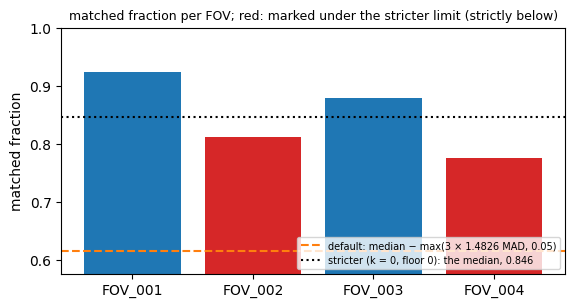

In [11]:
from starfinder.report import ReportLimits, RuleLimit

KEY = ["fov_id", "rule", "round", "axis"]


def rule_summary(record):
    # report.json "rules": per rule, the limit applied, the unit, whether it was evaluated and the FOVs it marks.
    frame = pd.DataFrame([dict(rule=rule, **{k: entry.get(k) for k in ("limit", "unit", "evaluated", "fovs_marked")})
                          for rule, entry in record["rules"].items()])
    return frame.astype({"fovs_marked": "Int64"})


def keys_of(frame):
    return {tuple(None if pd.isna(v) else v for v in row) for row in frame[KEY].itertuples(index=False)}


if not CHAIN:
    skipped("no report after the export (section 6)")
else:
    DEFAULT_ROWS = read_table(REPORT.path, "problematic_fovs", again)
    print("default limits:", ReportConfig().limits)
    display(rule_summary(again))
    print(f"problematic_fovs.csv under the default limits: {len(DEFAULT_ROWS)} rows")
    display(DEFAULT_ROWS)

    zero = RuleLimit(k=0.0, floor=0.0)
    STRICT = dataclasses.replace(MARKERS, limits=ReportLimits(shift_residual=zero, alignment_score=zero,
                                                              correct_form_fraction=zero, matched_fraction=zero,
                                                              spots_near_zero=0.9))
    STRICT_DIR = WORKSPACE / "tiny" / "report_strict"
    with timed("sample-tiny-v1: Dataset.report with the stricter limits"):
        STRICT_REPORT = dataset.report(SAMPLE, FOV_IDS, config=STRICT, output_dir=STRICT_DIR)
    STRICT_ROWS = read_table(STRICT_DIR, "problematic_fovs", STRICT_REPORT.record)
    print("\nstricter limits:", STRICT.limits)
    display(rule_summary(STRICT_REPORT.record))
    print(f"problematic_fovs.csv under the stricter limits: {len(STRICT_ROWS)} rows")
    display(STRICT_ROWS)
    included = keys_of(DEFAULT_ROWS) <= keys_of(STRICT_ROWS)
    print("the rows of the stricter limits include those of the default:", included,
          f"({len(keys_of(DEFAULT_ROWS))} of {len(keys_of(STRICT_ROWS))} rows)")
    assert included

    values = FOV_TABLE.set_index("fov_id")["matched_fraction"].astype(float)
    m = float(np.median(values))
    s = 1.4826 * float(np.median(np.abs(values - m)))
    default = ReportConfig().limits.matched_fraction
    marked = set(STRICT_ROWS.loc[STRICT_ROWS["rule"] == "matched_fraction", "fov_id"])
    fig, ax = plt.subplots(figsize=(6.5, 3.2))
    ax.bar(values.index, values.to_numpy(), color=["C3" if f in marked else "C0" for f in values.index])
    ax.axhline(m - max(default.k * s, default.floor), color="C1", ls="--",
               label="default: median − max(3 × 1.4826 MAD, 0.05)")
    ax.axhline(m, color="k", ls=":", label=f"stricter (k = 0, floor 0): the median, {m:.3f}")
    ax.set_ylim(max(0.0, values.min() - 0.2), min(1.0, values.max() + 0.1))
    ax.set_ylabel("matched fraction")
    ax.set_title("matched fraction per FOV; red: marked under the stricter limit (strictly below)", fontsize=9)
    ax.legend(fontsize=7, loc="lower right")
    plt.show()

**What to take from this.** Under the default limits, only the categorical rule `reads_no_cell`
marks a FOV of this sample: `FOV_002` retains reads but none of its cells (`n_molecules_retained`
1, `n_cells_retained` 0 in `fovs.csv`). No rule on values marks a FOV, and the alignment score is
not evaluated. With `k = 0` and floor 0, a rule on values marks every FOV whose value lies on the
rule's side of the median at all (any nonzero residual for the shift), hence the many rows of
the stricter table. A row is where to look, not a verdict on the FOV;
the limits are the user's to set, and the defaults stay provisional until the real example has
been reviewed.

## 9. The route after fusion on the single-plane scene

An export reaches the sample's cells by one of two routes: segmentation per FOV followed by
assembly (sections 5 and 6), or segmentation of the fused image. The report reads the route
from `export.json` and gives every table the same columns on both routes; only a few elements
differ ([docs/report-algorithms.md](../../docs/report-algorithms.md), "How the two routes
differ"). Among them are the cells attributed to a FOV: on the route per FOV, `n_cells` holds
the FOV's own cells and `n_cells_retained` those it retains; after fusion, both hold the cells of
the sample whose ownership centroid the FOV owns, so the two columns are equal.

The route after fusion segments a projection, so the sample here is `scene_plane`:
`sample-tiny-v1` with one-plane FOVs of 1 × 36 × 36 and a jitter of (0, 1.5, 1.5) voxels, made with
`dataclasses.replace` as the fixture of
[docs/stitching-assembly-validation.md](../../docs/stitching-assembly-validation.md) makes it.
The cell runs sections 2, 3 and 5 on it and exports it twice, each export in its own output
root, because the report reads the export at its fixed place `export/<sample>/`:

* on the **route per FOV**, as in section 5, with the fused image as a projection;
* on the **route after fusion**, in a copy of the output root without the export: the fused
  images `reference_stain` and `reference_merged`, a run `nucleus` that imports the scene's truth
  nuclei, projected onto the segmentation grid, and a run `cell` by `seeded_watershed` (sigma
  1 µm) on the fused `reference_merged`, seeded by the nuclei, as the fixture `seeded_runs` of
  [docs/sample-segmentation-validation.md](../../docs/sample-segmentation-validation.md) builds
  them. The watershed needs no model and is used for that reason; its cells are not compared
  with the truth.

The report of the route after fusion is written into the report root of `sample-tiny-v1`, as the
sample `scene_plane`, for the comparison page of section 10 (`output_dir` may name any folder).

In [12]:
from starfinder.assignment import AssignmentConfig
from starfinder.sample_output import SampleSegmentationConfig, SampleSegmentationRun, fused_grid
from starfinder.segmentation import LabelImportConfig, SeededWatershedConfig
from starfinder.stitching import load_placement

if not CHAIN:
    skipped("the two routes need the anndata and multiview-stitcher extras")
else:
    plane_book, tiny = sample_scene_preset("sample-tiny-v1")
    plane_config = dataclasses.replace(
        tiny, acquisition=dataclasses.replace(tiny.acquisition, fov_shape_zyx=(1, 36, 36),
                                              jitter_max_zyx=(0.0, 1.5, 1.5)),
        fov=dataclasses.replace(tiny.fov, shape_zyx=(1, 36, 36)))
    PLANE = WORKSPACE / "plane"
    PER_FOV, AFTER = PLANE / "per_fov", PLANE / "after_fusion"
    with timed("scene_plane: generate, run, assign, place, export on the route per FOV"), synchronous():
        plane_scene = generate_sample_scene(plane_book, config=plane_config)
        save_sample_scene(plane_scene, PLANE / "scene")
        write_inputs(plane_scene, ROUNDS, CHANNELS, PLANE / "input")
        plane_dataset = make_dataset(PLANE / "input", PER_FOV, plane_scene, plane_book)
        plane_checkpoints = CheckpointConfig(stages=STAGES, directory=PER_FOV / "checkpoints")
        plane_fovs = run_fovs(plane_dataset, FOV_IDS, plane_checkpoints)
        assign_by_mask_import(plane_fovs, PLANE / "scene", plane_scene, plane_checkpoints)
        _, plane_grids = save_truth_placement(PLANE / "scene", plane_scene, plane_config, PER_FOV)
        plane_dataset.export(SAMPLE, placement=PER_FOV / "stitching" / SAMPLE, output_dir=PER_FOV / "export" / SAMPLE,
                             config=ExportConfig(route="per_fov", fusion=FusionConfig(dimensionality="projection")))
    print("scene_plane: FOV shape", plane_config.acquisition.fov_shape_zyx, " FOVs", FOV_IDS)

    with timed("scene_plane: export on the route after fusion"), synchronous():
        shutil.copytree(PER_FOV, AFTER, ignore=lambda folder, names: ["export"] if Path(folder) == PER_FOV else [])
        after_dataset = make_dataset(PLANE / "input", AFTER, plane_scene, plane_book)
        fusion = FusionConfig(images=("reference_stain", "reference_merged"))
        segmentation_grid = fused_grid(load_placement(AFTER / "stitching" / SAMPLE), plane_grids, config=fusion)
        S_SEG, O_SEG, N_SEG = segmentation_grid.level("projection")
        # The truth nuclei on the segmentation grid: each pixel takes the label of the sample grid's nearest voxel.
        largest = plane_scene.sample_labels["nucleus"].max(axis=0)
        grid = plane_scene.sample_grid
        iy = np.floor((O_SEG[1] + np.arange(N_SEG[1]) * S_SEG[1] - grid.origin_zyx[1]) / grid.spacing_zyx[1]
                      + 0.5).astype(int)
        ix = np.floor((O_SEG[2] + np.arange(N_SEG[2]) * S_SEG[2] - grid.origin_zyx[2]) / grid.spacing_zyx[2]
                      + 0.5).astype(int)
        inside = ((iy >= 0) & (iy < largest.shape[0]))[:, None] & ((ix >= 0) & (ix < largest.shape[1]))[None, :]
        nuclei = np.where(inside, largest[iy.clip(0, largest.shape[0] - 1)[:, None],
                                          ix.clip(0, largest.shape[1] - 1)[None, :]], 0).astype(np.uint32)
        NUCLEI_FILE = PLANE / "truth" / "nuclei_projection.tif"
        save_volume(nuclei[np.newaxis], NUCLEI_FILE, metadata=segmentation_grid.level_metadata("projection"))
        segmentation = SampleSegmentationConfig(
            runs=(SampleSegmentationRun("nucleus", "nucleus", (), LabelImportConfig(str(NUCLEI_FILE), "nucleus")),
                  SampleSegmentationRun("cell", "cell", (("amplicon", "reference_merged"),),
                                        SeededWatershedConfig(sigma_um=1.0), seeds="nucleus")),
            cells="cell", nuclei="nucleus", assignment=AssignmentConfig())
        after_dataset.export(SAMPLE, placement=AFTER / "stitching" / SAMPLE, output_dir=AFTER / "export" / SAMPLE,
                             config=ExportConfig(route="after_fusion", fusion=fusion, segmentation=segmentation))
    print("segmentation grid:", N_SEG, " truth nuclei on it:", len(set(np.unique(nuclei)) - {0}))

scene_plane: FOV shape (1, 36, 36)  FOVs ['FOV_001', 'FOV_002', 'FOV_003', 'FOV_004']


segmentation grid: (1, 30, 31)  truth nuclei on it: 9


The two reports, with the marker configuration of section 6. The cell prints the cell and
molecule columns of each route's `fovs.csv` and the two `population.csv` (the accounting of the
export), and asserts that after fusion `n_cells` equals `n_cells_retained` for every FOV. The
populations of the duplicate rule are not applicable after fusion: null, and named by no row of
`unavailable.csv`.

In [13]:
CELL_COLUMNS = ["fov_id", "n_cells", "n_cells_retained", "n_molecules", "n_molecules_retained", "reads_in_cells",
                "owned_area_um2", "cell_density_per_mm2"]

if not CHAIN:
    skipped("no export of scene_plane")
else:
    with timed("scene_plane: Dataset.report on both routes"):
        ROUTES = {"per_fov": plane_dataset.report(SAMPLE, FOV_IDS, config=MARKERS),
                  "after_fusion": after_dataset.report(SAMPLE, FOV_IDS, config=MARKERS,
                                                       output_dir=OUTPUT / "report" / "scene_plane")}
    route_tables = {}
    for route, result in ROUTES.items():
        print(f"route {route}: the record's route {result.record['route']!r}, folder {clean(result.path)}")
        route_tables[route] = read_table(result.path, "fovs", result.record)
        display(route_tables[route][CELL_COLUMNS].round(3))
    population = pd.concat({route: read_table(r.path, "population", r.record).set_index("population")
                            for route, r in ROUTES.items()}, axis=1)
    display(population)
    after_fovs = route_tables["after_fusion"]
    equal = after_fovs["n_cells"].tolist() == after_fovs["n_cells_retained"].tolist()
    print("after fusion, n_cells equals n_cells_retained for every FOV:", equal)
    assert [r.record["route"] for r in ROUTES.values()] == ["per_fov", "after_fusion"]
    assert equal and after_fovs["n_cells"].notna().all()
    assert list(route_tables["per_fov"].columns) == list(after_fovs.columns)

route per_fov: the record's route 'per_fov', folder <workspace>/plane/per_fov/report/sample


,fov_id,n_cells,n_cells_retained,n_molecules,n_molecules_retained,reads_in_cells,owned_area_um2,cell_density_per_mm2
0,FOV_001,4,3,21,18,14,229.50,13071.895
1,FOV_002,4,1,10,5,5,228.00,4385.965
2,FOV_003,4,3,20,16,16,224.25,13377.926
3,FOV_004,6,2,17,9,9,230.00,8695.652


route after_fusion: the record's route 'after_fusion', folder <workspace>/tiny/output/report/scene_plane


,fov_id,n_cells,n_cells_retained,n_molecules,n_molecules_retained,reads_in_cells,owned_area_um2,cell_density_per_mm2
0,FOV_001,3,3,21,18,16,229.50,13071.895
1,FOV_002,0,0,10,5,3,228.00,0.000
2,FOV_003,3,3,20,12,9,224.25,13377.926
3,FOV_004,3,3,17,14,14,230.00,13043.478


per_fov           after_fusion          
                                      cells molecules        cells molecules
population                                                                  
input                                    18        68            9        68
retained                                  9        48            9        49
excluded_not_owner                        7         2            0        19
excluded_fov_not_placed                   0         0            0         0
excluded_duplicate_observation            2      <NA>         <NA>      <NA>
excluded_cell_not_owner                <NA>        11         <NA>         0
excluded_cell_duplicate_observation    <NA>         7         <NA>      <NA>
excluded_outside_grid                  <NA>         0         <NA>         0
counted                                   8        44            9        42

after fusion, n_cells equals n_cells_retained for every FOV: True


## 10. `Dataset.compare_samples`

`Dataset.compare_samples(samples)` reads the finished sample reports under the report root
(`<output>/report/` by default): each sample's `report.json`, checked with `read_report`, and its
`tables/fovs.csv`. It reads no run record, placement or export and recomputes nothing. It writes
the comparison page `index.html` and `samples.csv`, one row per sample in the order given, each
column a copy of a key of the sample's `report.json`
([docs/report-algorithms.md](../../docs/report-algorithms.md), "The comparison page"). The page
also draws three box plots by sample from the reports' `fovs.csv` (spots, matched fraction and
cells per FOV). A sample without a report is a row marked `missing`.

The two samples are `sample` (the report of section 6: `sample-tiny-v1` on the route per FOV)
and `scene_plane` (the report of section 9 on the route after fusion). `generated_at` and
`report_sha256` change with every execution, because a report records the time it was made, so
the cell prints them masked and checks the SHA-256 against the file.

In [14]:
if not CHAIN:
    skipped("no sample report (sections 6 and 9)")
else:
    with timed("Dataset.compare_samples"):
        COMPARISON = dataset.compare_samples([SAMPLE, "scene_plane"])
    print("report root:", clean(COMPARISON.path), " entries:", sorted(p.name for p in COMPARISON.path.iterdir()))
    samples = read_table(COMPARISON.path, "samples", COMPARISON.record)
    display(samples.assign(generated_at="<UTC time>",
                           report_sha256=[f"<{len(v)} hex characters>" for v in samples["report_sha256"]]))
    assert list(samples["sample"]) == [SAMPLE, "scene_plane"] and list(samples["report"]) == ["present", "present"]
    for name, row in samples.set_index("sample").iterrows():
        assert row["report_sha256"] == hashlib.sha256((COMPARISON.path / name / "report.json").read_bytes()).hexdigest()
    print(f"{len(samples)} rows, both reports present, each report_sha256 the SHA-256 of its report.json: True")
    print("box plots (sample, FOVs with a value):", {column: [(s["sample"], s["fovs"]) for s in slots]
                                                     for column, slots in COMPARISON.record["box_plots"].items()})

report root: <workspace>/tiny/output/report  entries: ['index.html', 'sample', 'samples.csv', 'scene_plane']


,sample,report,report_sha256,generated_at,route,fovs_expected,fovs_succeeded,spots_median_per_fov,matched_fraction,counted_cells,cells_median_per_fov
0,sample,present,<64 hex characters>,<UTC time>,per_fov,4,4,29.5,0.843478,8,2.0
1,scene_plane,present,<64 hex characters>,<UTC time>,after_fusion,4,4,25.0,0.784091,9,3.0


2 rows, both reports present, each report_sha256 the SHA-256 of its report.json: True
box plots (sample, FOVs with a value): {'spots': [('sample', 4), ('scene_plane', 4)], 'matched_fraction': [('sample', 4), ('scene_plane', 4)], 'n_cells_retained': [('sample', 4), ('scene_plane', 4)]}


## 11. Clean up

The notebook wrote only inside its temporary workspace: the two scenes and their inputs, the
output roots (run records, checkpoints, reference images, goodSpots tables, assignments,
placements and exports), the sample reports, the report with the stricter limits and the
comparison page. The next cell prints what was written, the sizes of the pages, and the
wall-clock time of the slower steps, measured by `timed` at one thread on this host. **The times
and the sizes are the only printed values that change between executions**: the page shows when
the report was generated and the times of the run's steps, which change from one run to the
next, so its size changes too. The last cell removes the workspace.

In [15]:
written = [p for p in WORKSPACE.rglob("*") if p.is_file()]
print(f"{len(written)} files written, all under {sorted({p.relative_to(WORKSPACE).parts[0] for p in written})}")
print(f"size of the workspace: {sum(p.stat().st_size for p in written) / 2**20:.1f} MiB")
for p in sorted(p for p in written if p.name in ("report.html", "index.html")):
    print(f"size of {clean(p)}: {p.stat().st_size / 2**10:.1f} KiB")
print("\nwall-clock time of the slower steps (one thread, this host; indicative, varies between runs):")
for label, seconds in TIMINGS.items():
    print(f"  {seconds:6.2f} s  {label}")

513 files written, all under ['plane', 'tiny']
size of the workspace: 14.0 MiB
size of <workspace>/plane/per_fov/report/sample/report.html: 1219.2 KiB
size of <workspace>/tiny/output/report/index.html: 58.9 KiB
size of <workspace>/tiny/output/report/sample/report.html: 1291.3 KiB
size of <workspace>/tiny/output/report/scene_plane/report.html: 1170.4 KiB
size of <workspace>/tiny/report_strict/report.html: 1296.3 KiB

wall-clock time of the slower steps (one thread, this host; indicative, varies between runs):
    0.42 s  sample-tiny-v1: generate and save the scene, write the inputs
    1.10 s  sample-tiny-v1: FOV.run with checkpoints (4 FOVs)
    1.40 s  Dataset.report after the per-FOV processing
    0.34 s  sample-tiny-v1: mask import and FOV.assign (4 FOVs)
    2.63 s  sample-tiny-v1: Dataset.export on the route per FOV (dimensionality both)
    2.30 s  sample-tiny-v1: Dataset.report after the export
    2.13 s  sample-tiny-v1: Dataset.report with the stricter limits
    2.54 s  scen

In [16]:
_workspace.cleanup()
print("workspace removed:", not WORKSPACE.exists())

workspace removed: True
